## Setup e imports

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import json
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"

RESULTS = Path("../experiments/results")
PLANS = Path("../experiments/plans")
FIGURES = Path("../experiments/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Load results
df = pl.read_parquet(RESULTS / "experiment_results.parquet")
with open(RESULTS / "experiment_results.json") as f:
    results_json = json.load(f)

print(f"Loaded {df.shape[0]} query results")
df

Loaded 23 query results


query_id,experiment,description,row_count,mean_time_s,min_time_s,max_time_s,std_time_s
str,str,str,i64,f64,f64,f64,f64
"""E1-Q1""","""E1_filter_vs_no_filter""","""JOIN pathology-masterfile, no …",1225,0.004403,0.003127,0.008294,0.001646
"""E1-Q2""","""E1_filter_vs_no_filter""","""JOIN pathology-masterfile, fil…",553,0.005147,0.003949,0.005944,0.000645
"""E1-Q3""","""E1_filter_vs_no_filter""","""JOIN pathology-masterfile, fil…",155,0.005088,0.004436,0.006037,0.000597
"""E1-Q4""","""E1_filter_vs_no_filter""","""JOIN masterfile-lung_cancer, n…",412269,0.448861,0.432886,0.499346,0.018677
"""E1-Q5""","""E1_filter_vs_no_filter""","""JOIN masterfile-lung_cancer, f…",332688,0.359527,0.349525,0.37545,0.007399
…,…,…,…,…,…,…,…
"""E3-Q8""","""E3_join_order""","""3-way: treatment -> cause_of_d…",7795,0.015899,0.010775,0.021941,0.003336
"""E5-Q1""","""E5_join_aggregation""","""COUNT by cancer_type after 3-w…",4,0.031493,0.027237,0.03942,0.004034
"""E5-Q2""","""E5_join_aggregation""","""COUNT DISTINCT patients by tre…",4,0.012396,0.009553,0.019171,0.002833


---

## Visão geral: tempo por query

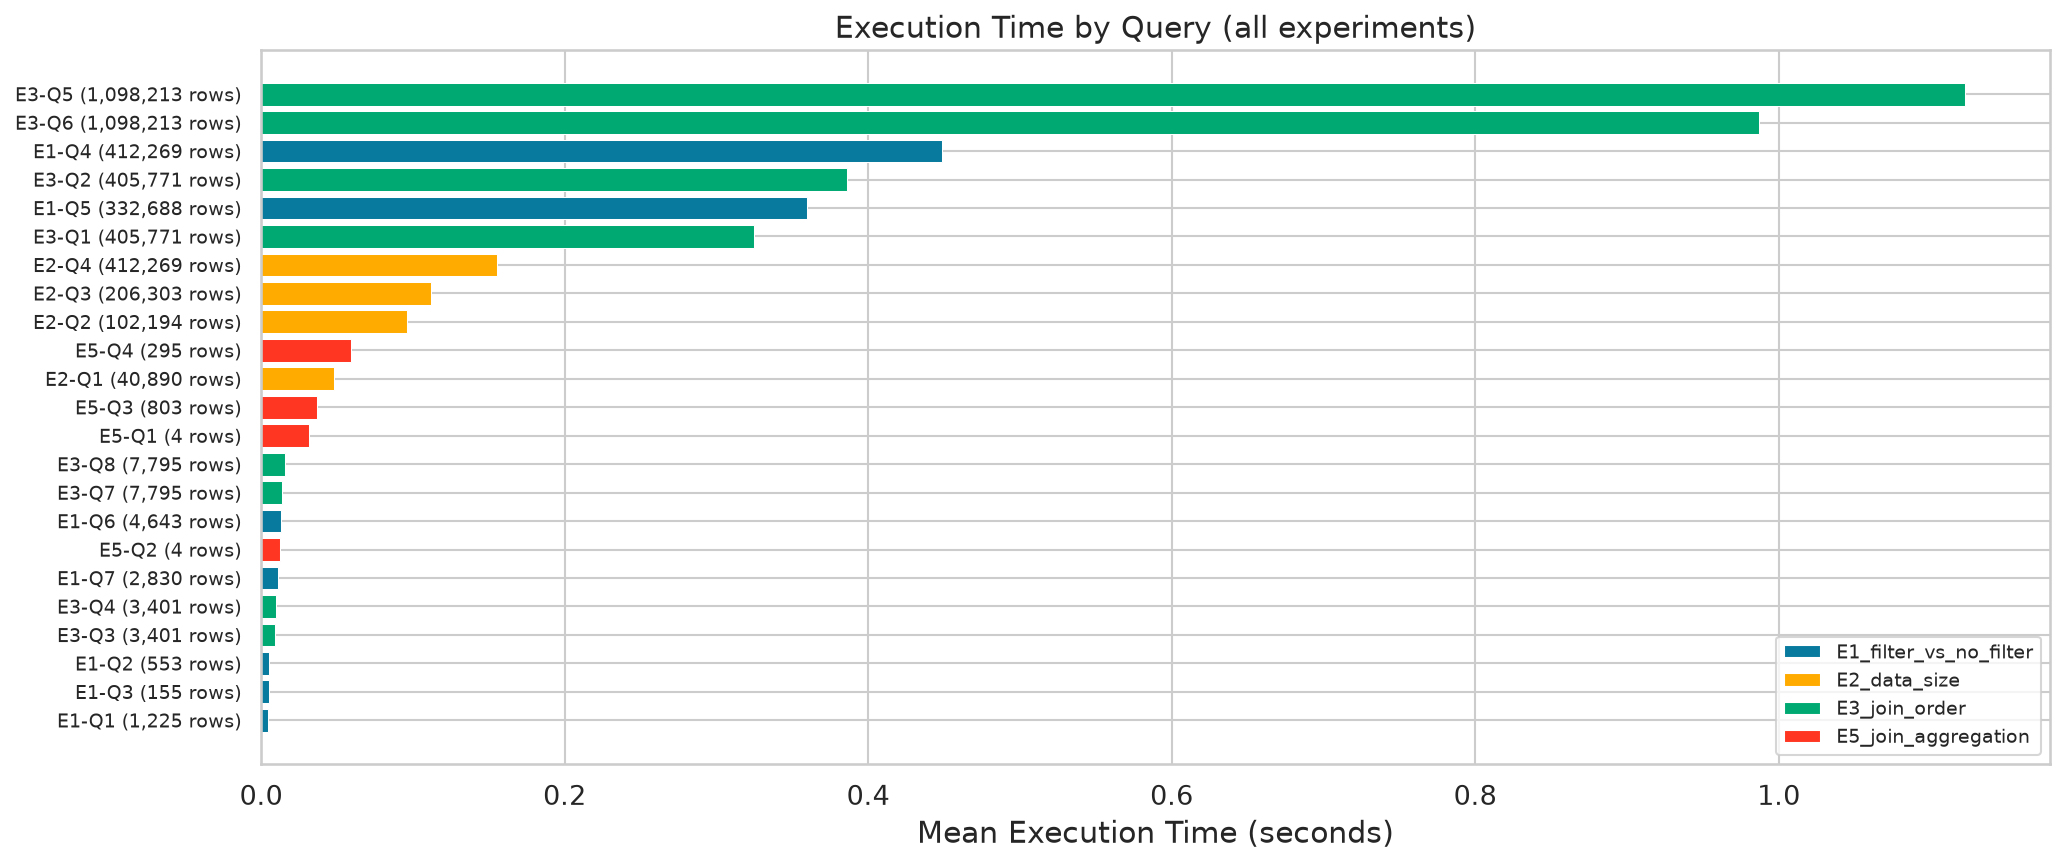

In [2]:
fig, ax = plt.subplots(figsize=(14, 6))

data = df.sort("mean_time_s", descending=True)

colors = []
palette = {"E1_filter_vs_no_filter": "#077A9D", "E2_data_size": "#FFAB00",
           "E3_join_order": "#00A972", "E5_join_aggregation": "#FF3621"}

for exp in data["experiment"].to_list():
    colors.append(palette.get(exp, "#919191"))

bars = ax.barh(
    range(len(data)),
    data["mean_time_s"].to_list(),
    color=colors,
    edgecolor="white",
    linewidth=0.5,
)

ax.set_yticks(range(len(data)))
ax.set_yticklabels([f"{qid} ({rc:,} rows)" for qid, rc in
                     zip(data["query_id"].to_list(), data["row_count"].to_list())],
                    fontsize=9)
ax.set_xlabel("Mean Execution Time (seconds)")
ax.set_title("Execution Time by Query (all experiments)")
ax.invert_yaxis()

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=l) for l, c in palette.items()]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / "00_overview_all_queries.png")
plt.show()

---

## E1: Filtro vs. Sem Filtro (tabelas pequenas)

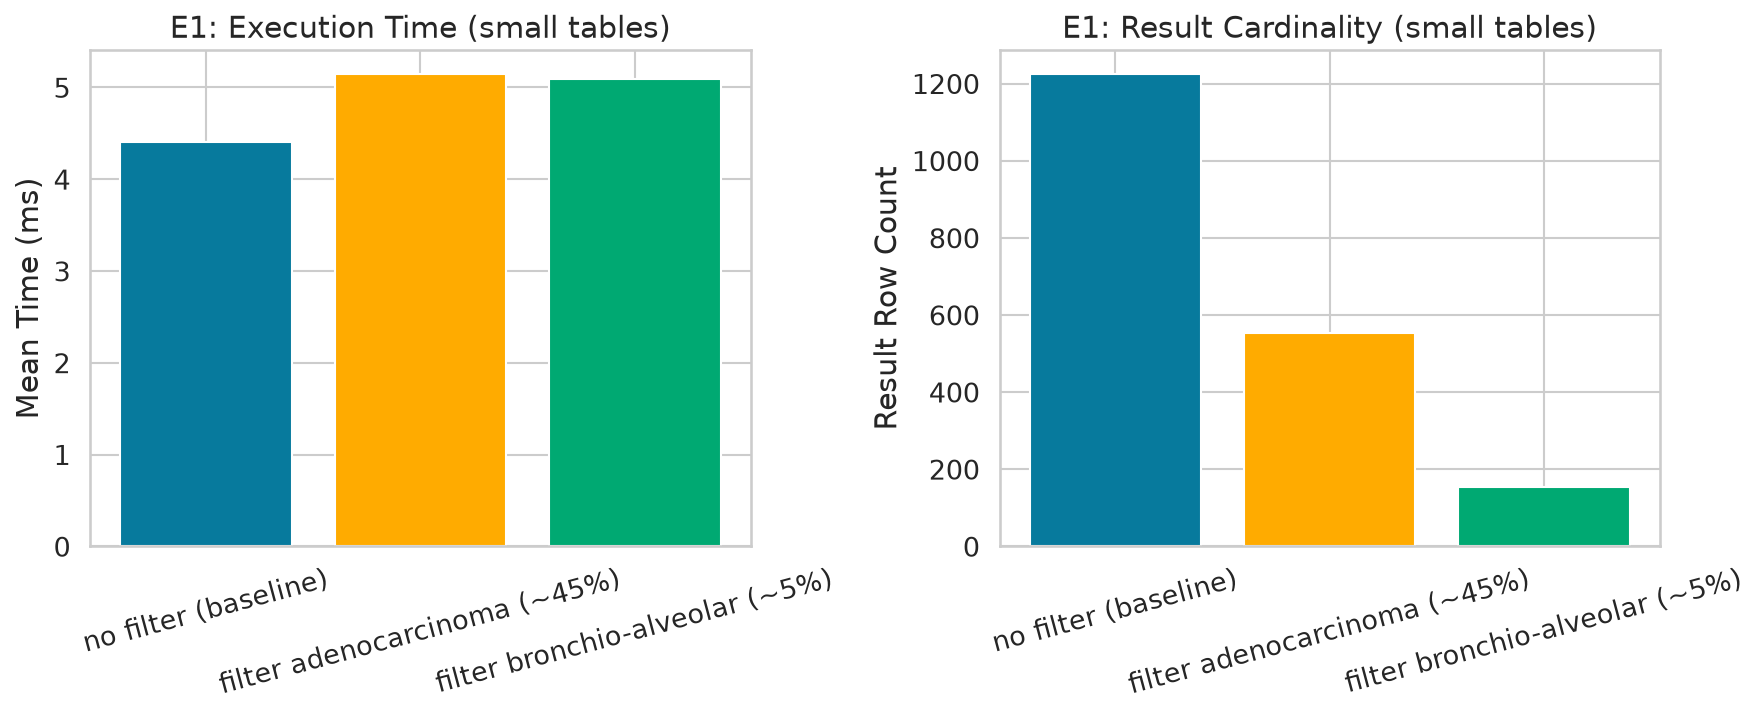

In [3]:
e1_small = df.filter(pl.col("query_id").is_in(["E1-Q1", "E1-Q2", "E1-Q3"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Tempo
labels = e1_small["description"].str.replace("JOIN pathology-masterfile, ", "").to_list()
times = e1_small["mean_time_s"].to_list()
rows = e1_small["row_count"].to_list()

ax1.bar(labels, [t * 1000 for t in times], color=["#077A9D", "#FFAB00", "#00A972"])
ax1.set_ylabel("Mean Time (ms)")
ax1.set_title("E1: Execution Time (small tables)")
ax1.tick_params(axis="x", rotation=15)

# Cardinalidade
ax2.bar(labels, rows, color=["#077A9D", "#FFAB00", "#00A972"])
ax2.set_ylabel("Result Row Count")
ax2.set_title("E1: Result Cardinality (small tables)")
ax2.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(FIGURES / "01_e1_filter_small_tables.png")
plt.show()

---

## E1: Filtro vs. Sem Filtro (tabelas grandes)

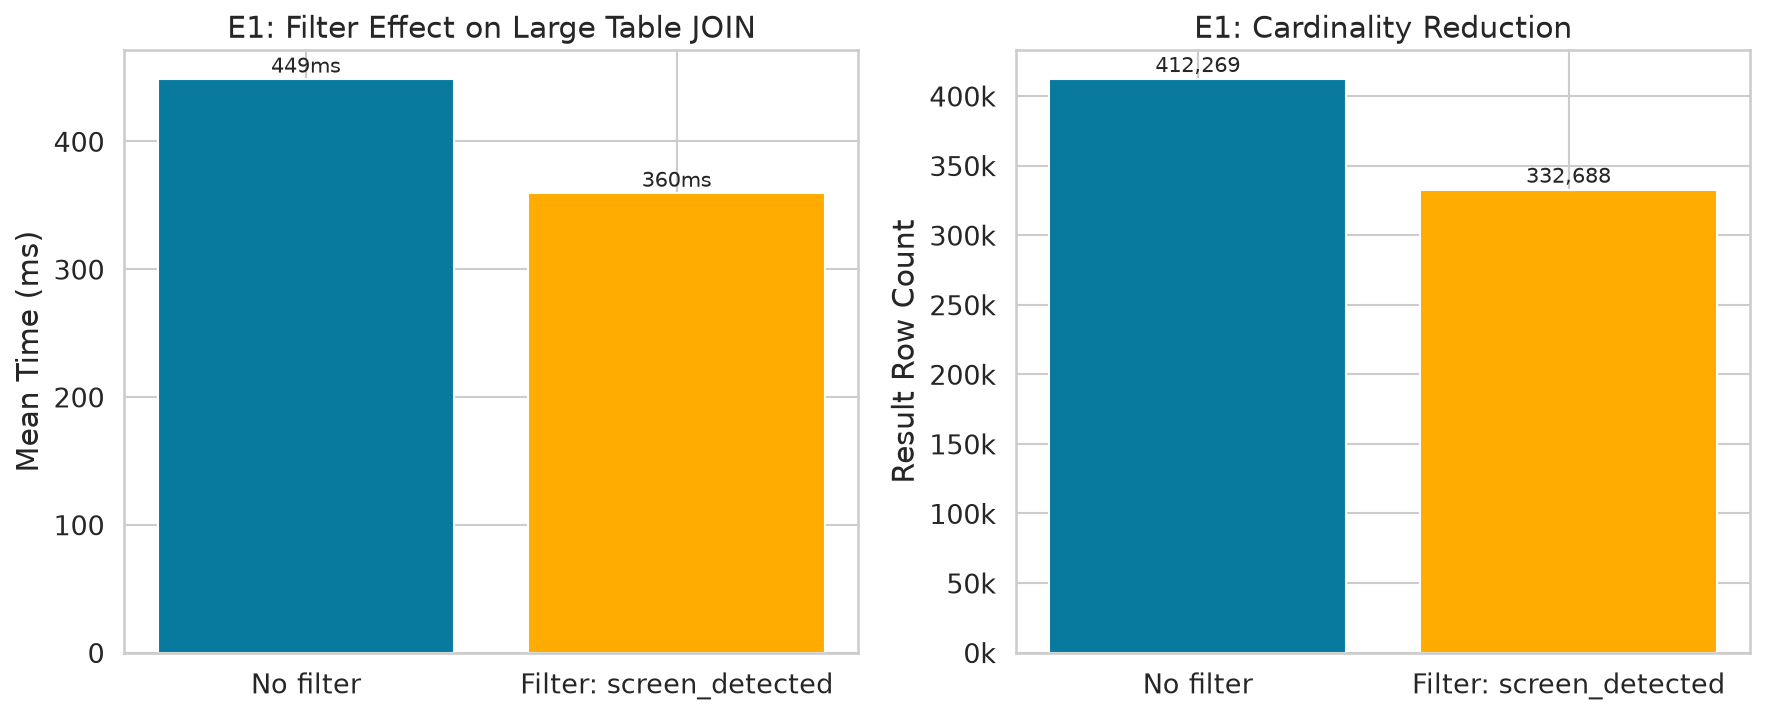

Time reduction with filter: 19.9%
Row reduction: 79,581 rows (19.3%)


In [4]:
e1_large = df.filter(pl.col("query_id").is_in(["E1-Q4", "E1-Q5"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

labels = ["No filter", "Filter: screen_detected"]
times = e1_large["mean_time_s"].to_list()
rows = e1_large["row_count"].to_list()

ax1.bar(labels, [t * 1000 for t in times], color=["#077A9D", "#FFAB00"])
ax1.set_ylabel("Mean Time (ms)")
ax1.set_title("E1: Filter Effect on Large Table JOIN")

for i, (t, r) in enumerate(zip(times, rows)):
    ax1.text(i, t * 1000 + 5, f"{t*1000:.0f}ms", ha="center", fontsize=10)

ax2.bar(labels, rows, color=["#077A9D", "#FFAB00"])
ax2.set_ylabel("Result Row Count")
ax2.set_title("E1: Cardinality Reduction")
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

for i, r in enumerate(rows):
    ax2.text(i, r + 5000, f"{r:,}", ha="center", fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES / "02_e1_filter_large_tables.png")
plt.show()

reduction = (1 - times[1] / times[0]) * 100
print(f"Time reduction with filter: {reduction:.1f}%")
print(f"Row reduction: {rows[0] - rows[1]:,} rows ({(1 - rows[1]/rows[0])*100:.1f}%)")

---

## E2: Escalabilidade (tamanho dos dados)

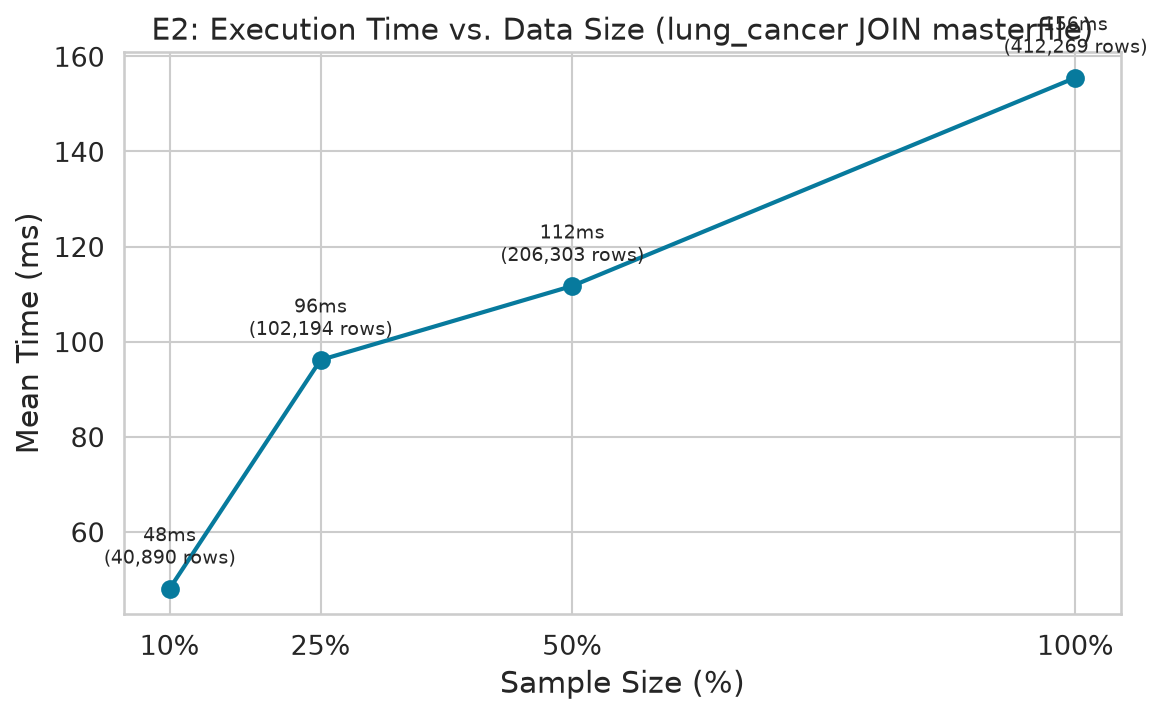

In [5]:
e2 = df.filter(pl.col("experiment") == "E2_data_size").sort("row_count")

fig, ax = plt.subplots(figsize=(8, 5))

pcts = [10, 25, 50, 100]
times = e2["mean_time_s"].to_list()
rows = e2["row_count"].to_list()

ax.plot(pcts, [t * 1000 for t in times], "o-", color="#077A9D", linewidth=2, markersize=8)

for p, t, r in zip(pcts, times, rows):
    ax.annotate(f"{t*1000:.0f}ms\n({r:,} rows)", (p, t * 1000),
                textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9)

ax.set_xlabel("Sample Size (%)")
ax.set_ylabel("Mean Time (ms)")
ax.set_title("E2: Execution Time vs. Data Size (lung_cancer JOIN masterfile)")
ax.set_xticks(pcts)
ax.set_xticklabels(["10%", "25%", "50%", "100%"])

plt.tight_layout()
plt.savefig(FIGURES / "03_e2_data_size.png")
plt.show()

---

## E3: Ordem dos JOINs (3-way com lung_cancer)

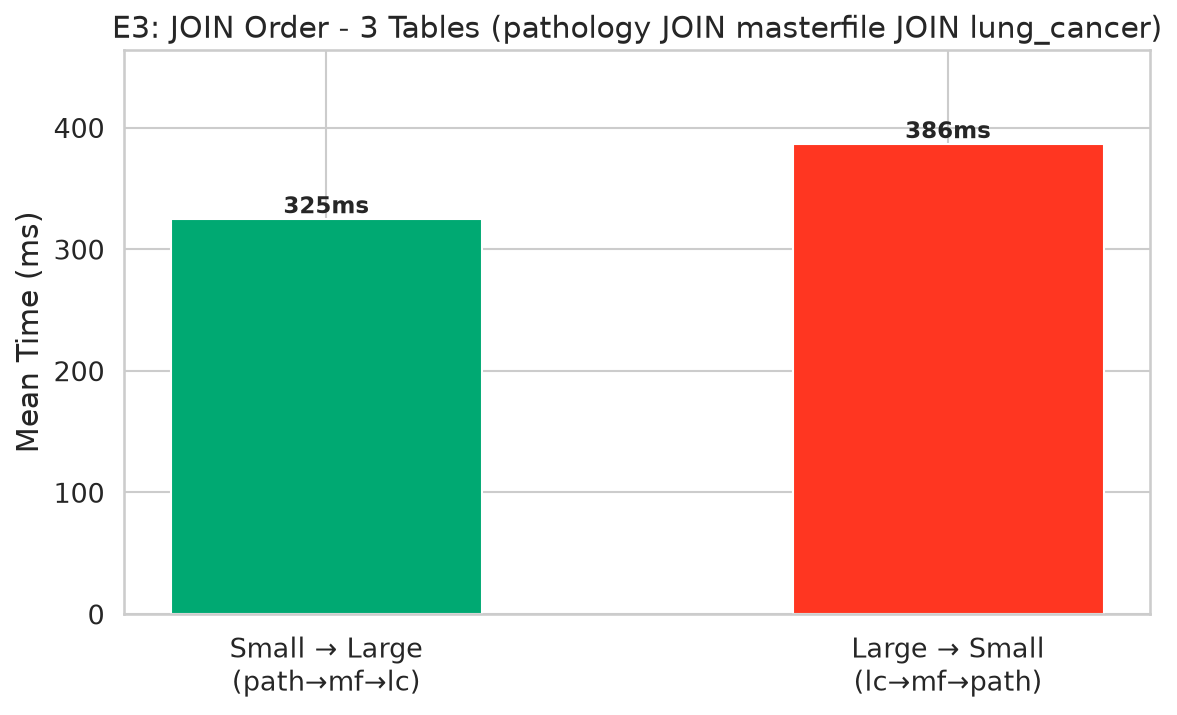

Difference: 16.0% — DuckDB reorders internally, so order in SQL has minimal effect


In [6]:
e3_lc = df.filter(pl.col("query_id").is_in(["E3-Q1", "E3-Q2"]))

fig, ax = plt.subplots(figsize=(8, 5))

labels = ["Small → Large\n(path→mf→lc)", "Large → Small\n(lc→mf→path)"]
times = e3_lc["mean_time_s"].to_list()

bars = ax.bar(labels, [t * 1000 for t in times], color=["#00A972", "#FF3621"], width=0.5)

for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f"{t*1000:.0f}ms", ha="center", fontsize=11, fontweight="bold")

ax.set_ylabel("Mean Time (ms)")
ax.set_title("E3: JOIN Order - 3 Tables (pathology JOIN masterfile JOIN lung_cancer)")
ax.set_ylim(0, max(times) * 1000 * 1.2)

plt.tight_layout()
plt.savefig(FIGURES / "04_e3_join_order_3way.png")
plt.show()

diff = abs(times[0] - times[1]) / max(times) * 100
print(f"Difference: {diff:.1f}% — DuckDB reorders internally, so order in SQL has minimal effect")

---

## E3: Ordem dos JOINs (4-way)

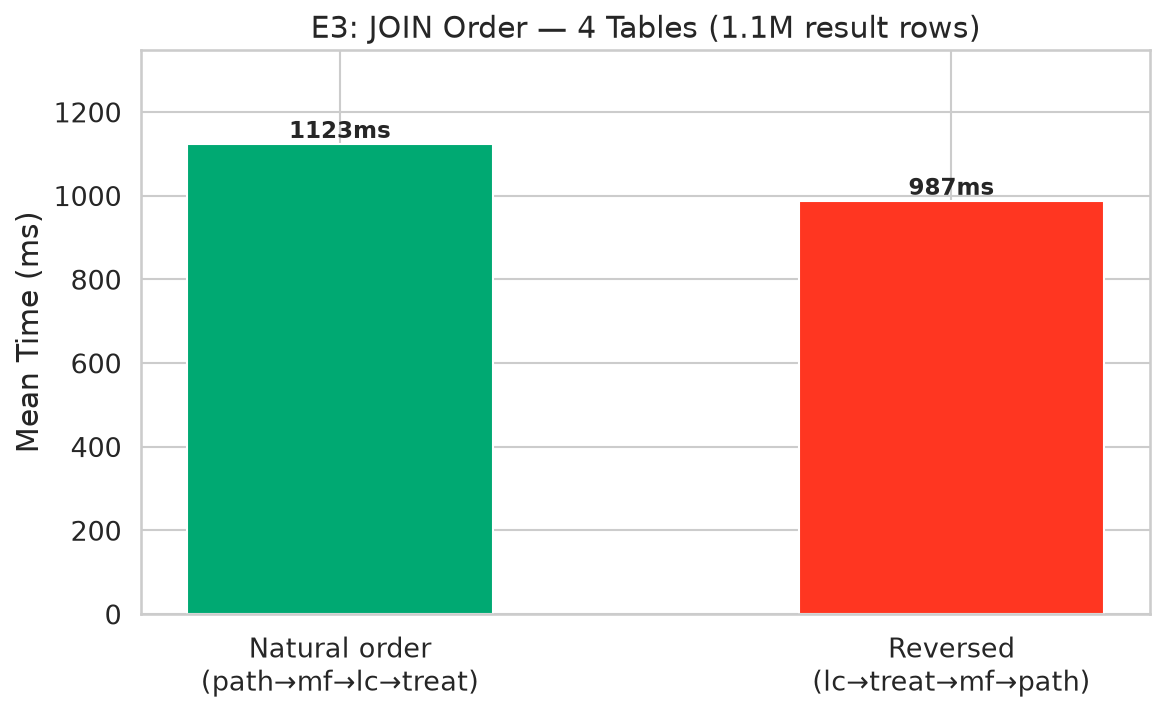

In [7]:
e3_4way = df.filter(pl.col("query_id").is_in(["E3-Q5", "E3-Q6"]))

fig, ax = plt.subplots(figsize=(8, 5))

labels = ["Natural order\n(path→mf→lc→treat)", "Reversed\n(lc→treat→mf→path)"]
times = e3_4way["mean_time_s"].to_list()

bars = ax.bar(labels, [t * 1000 for t in times], color=["#00A972", "#FF3621"], width=0.5)

for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
            f"{t*1000:.0f}ms", ha="center", fontsize=11, fontweight="bold")

ax.set_ylabel("Mean Time (ms)")
ax.set_title("E3: JOIN Order — 4 Tables (1.1M result rows)")
ax.set_ylim(0, max(times) * 1000 * 1.2)

plt.tight_layout()
plt.savefig(FIGURES / "05_e3_join_order_4way.png")


---

## E5: Agregação antes vs. depois do JOIN

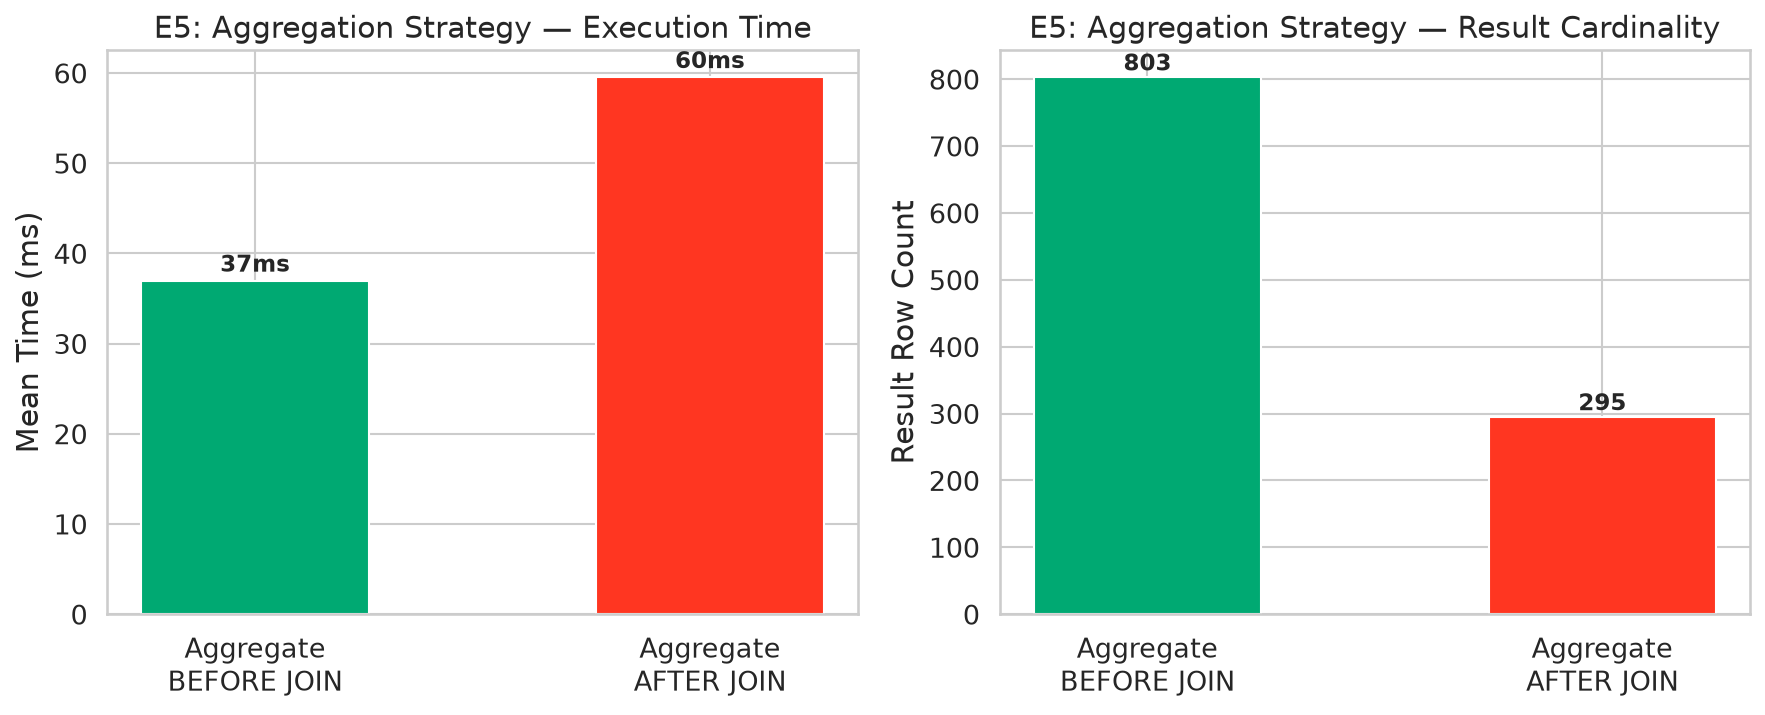

Pre-aggregation speedup: 37.9%


In [8]:
e5_agg = df.filter(pl.col("query_id").is_in(["E5-Q3", "E5-Q4"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

labels = ["Aggregate\nBEFORE JOIN", "Aggregate\nAFTER JOIN"]
times = e5_agg["mean_time_s"].to_list()
rows = e5_agg["row_count"].to_list()

bars1 = ax1.bar(labels, [t * 1000 for t in times], color=["#00A972", "#FF3621"], width=0.5)
for bar, t in zip(bars1, times):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{t*1000:.0f}ms", ha="center", fontsize=11, fontweight="bold")
ax1.set_ylabel("Mean Time (ms)")
ax1.set_title("E5: Aggregation Strategy — Execution Time")

bars2 = ax2.bar(labels, rows, color=["#00A972", "#FF3621"], width=0.5)
for bar, r in zip(bars2, rows):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
             f"{r:,}", ha="center", fontsize=11, fontweight="bold")
ax2.set_ylabel("Result Row Count")
ax2.set_title("E5: Aggregation Strategy — Result Cardinality")

plt.tight_layout()
plt.savefig(FIGURES / "06_e5_aggregation.png")
plt.show()

speedup = (1 - times[0] / times[1]) * 100
print(f"Pre-aggregation speedup: {speedup:.1f}%")

---

## E4: Plano do otimizador (exemplo: 4-way join)

In [9]:
# Mostrar o EXPLAIN ANALYZE do 4-way join
plan_file = PLANS / "E3-Q5_explain_analyze.txt"
if plan_file.exists():
    print("EXPLAIN ANALYZE — E3-Q5 (4-way join, natural order):")
    print("=" * 70)
    print(plan_file.read_text())
else:
    print("Plan file not found")

EXPLAIN ANALYZE — E3-Q5 (4-way join, natural order):
┌─────────────────────────────────────┐
│┌───────────────────────────────────┐│
││    Query Profiling Information    ││
│└───────────────────────────────────┘│
└─────────────────────────────────────┘
EXPLAIN ANALYZE SELECT p.slide_id, p.cancer_type, m.patient_id, lc.modality, t.treatment_category             FROM pathology p             JOIN masterfile m ON p.slide_id = m.slide_id             JOIN lung_cancer lc ON m.patient_id = lc.patient_id             JOIN treatment t ON m.patient_id = t.patient_id
┌────────────────────────────────────────────────┐
│┌──────────────────────────────────────────────┐│
││              Total Time: 0.0294s             ││
│└──────────────────────────────────────────────┘│
└────────────────────────────────────────────────┘
┌───────────────────────────┐
│           QUERY           │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│      EXPLAIN_ANALYZE      │
│    ────────────────────   │
│   

---

## E4: Comparar EXPLAIN vs. EXPLAIN ANALYZE

In [10]:
# Comparar plano estimado vs. real para queries selecionadas
print("EXPLAIN (estimated) — E3-Q5:")
print("=" * 70)
explain_file = PLANS / "E3-Q5_explain.txt"
if explain_file.exists():
    print(explain_file.read_text())

print("\n\nEXPLAIN ANALYZE (actual) — E3-Q5:")
print("=" * 70)
analyze_file = PLANS / "E3-Q5_explain_analyze.txt"
if analyze_file.exists():
    print(analyze_file.read_text())

EXPLAIN (estimated) — E3-Q5:
┌───────────────────────────┐
│         PROJECTION        │
│    ────────────────────   │
│          slide_id         │
│        cancer_type        │
│         patient_id        │
│          modality         │
│     treatment_category    │
│                           │
│      ~1,131,307 rows      │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│         HASH_JOIN         │
│    ────────────────────   │
│      Join Type: INNER     │
│                           │
│        Conditions:        ├──────────────┐
│  patient_id = patient_id  │              │
│                           │              │
│      ~1,131,307 rows      │              │
└─────────────┬─────────────┘              │
┌─────────────┴─────────────┐┌─────────────┴─────────────┐
│          SEQ_SCAN         ││         HASH_JOIN         │
│    ────────────────────   ││    ────────────────────   │
│           Table:          ││      Join Type: INNER     │
│   nlst.main.lung_cancer   ││

---

## Tabela resumo para o artigo

In [11]:
# Tabela formatada para incluir no artigo
summary = df.select([
    pl.col("query_id"),
    pl.col("experiment").str.replace("E1_filter_vs_no_filter", "E1: Filter").str.replace("E2_data_size", "E2: Size").str.replace("E3_join_order", "E3: Order").str.replace("E5_join_aggregation", "E5: Aggregation"),
    pl.col("row_count"),
    (pl.col("mean_time_s") * 1000).round(1).alias("mean_ms"),
    (pl.col("min_time_s") * 1000).round(1).alias("min_ms"),
    (pl.col("max_time_s") * 1000).round(1).alias("max_ms"),
    (pl.col("std_time_s") * 1000).round(1).alias("std_ms"),
])

print(summary)

# Export as CSV for LaTeX
summary.write_csv(RESULTS / "summary_for_article.csv")
print(f"\nSaved to {RESULTS / 'summary_for_article.csv'}")

shape: (23, 7)
┌──────────┬─────────────────┬───────────┬─────────┬────────┬────────┬────────┐
│ query_id ┆ experiment      ┆ row_count ┆ mean_ms ┆ min_ms ┆ max_ms ┆ std_ms │
│ ---      ┆ ---             ┆ ---       ┆ ---     ┆ ---    ┆ ---    ┆ ---    │
│ str      ┆ str             ┆ i64       ┆ f64     ┆ f64    ┆ f64    ┆ f64    │
╞══════════╪═════════════════╪═══════════╪═════════╪════════╪════════╪════════╡
│ E1-Q1    ┆ E1: Filter      ┆ 1225      ┆ 4.4     ┆ 3.1    ┆ 8.3    ┆ 1.6    │
│ E1-Q2    ┆ E1: Filter      ┆ 553       ┆ 5.1     ┆ 3.9    ┆ 5.9    ┆ 0.6    │
│ E1-Q3    ┆ E1: Filter      ┆ 155       ┆ 5.1     ┆ 4.4    ┆ 6.0    ┆ 0.6    │
│ E1-Q4    ┆ E1: Filter      ┆ 412269    ┆ 448.9   ┆ 432.9  ┆ 499.3  ┆ 18.7   │
│ E1-Q5    ┆ E1: Filter      ┆ 332688    ┆ 359.5   ┆ 349.5  ┆ 375.4  ┆ 7.4    │
│ …        ┆ …               ┆ …         ┆ …       ┆ …      ┆ …      ┆ …      │
│ E3-Q8    ┆ E3: Order       ┆ 7795      ┆ 15.9    ┆ 10.8   ┆ 21.9   ┆ 3.3    │
│ E5-Q1    ┆ E5: Aggregat

---

## Salvar todas as figuras

In [12]:
print("Figures saved to:")
for f in sorted(FIGURES.glob("*.png")):
    print(f"  {f.name} ({f.stat().st_size / 1024:.0f} KB)")

Figures saved to:
  00_overview_all_queries.png (331 KB)
  01_e1_filter_small_tables.png (241 KB)
  02_e1_filter_large_tables.png (160 KB)
  03_e2_data_size.png (170 KB)
  04_e3_join_order_3way.png (103 KB)
  05_e3_join_order_4way.png (107 KB)
  06_e5_aggregation.png (187 KB)
